
# Analisis Ilmiah Eksperimen Replay Protection pada Microservices

**Dataset:** `replay-2026-11-12T21-04-35-038Z-24266fa7`  
**Versi analisis:** 1.0  
**Tujuan:** memvalidasi integritas data, menghitung ulang metrik dari observasi request, menguji pola performa secara eksploratif, dan menginterpretasikan hasil sesuai batas bukti.

> **Prinsip reproduksibilitas.** Notebook ini tidak mengimplementasikan ulang algoritma validasi utama. Sel validasi memanggil `analysis/analyze_replay_protection.py`, yang menjadi sumber resmi perhitungan dan validasi. Analisis statistik tambahan di notebook bekerja pada keluaran terverifikasi dan observasi mentah, tanpa mengubah data eksperimen.



## 1. Pertanyaan penelitian dan ruang lingkup

Eksperimen membandingkan empat konfigurasi pengelolaan replay state:

1. **In-memory:** `Set` lokal pada proses Order Service.
2. **Redis:** operasi atomik `SET NX` pada penyimpanan bersama, tanpa TTL selama eksperimen.
3. **Redis TTL:** `SET NX PX`, dengan TTL mengikuti sisa masa berlaku JWT.
4. **MySQL:** tabel InnoDB dengan kunci unik/primary key pada hash `jti`.

Setiap konfigurasi diuji dengan **1, 2, dan 3 replika**, masing-masing sebanyak **3 repetisi** (12 konfigurasi; 36 unit konfigurasi-repetisi).

### Semantik token

Token dalam eksperimen ini adalah **one-time-use service token**: satu `jti` hanya boleh mengotorisasi satu protected operation. Ini merupakan asumsi desain eksperimen, bukan klaim bahwa semua JWT access token secara umum bersifat sekali pakai.

### Pertanyaan analisis

- **RQ1 — Keamanan:** seberapa efektif setiap strategi mendeteksi penggunaan ulang `jti`?
- **RQ2 — Skalabilitas replika:** bagaimana penambahan replika memengaruhi deteksi replay, khususnya replay lintas replika?
- **RQ3 — Performa:** bagaimana latency end-to-end, latency replay-store, dan throughput berbeda antarstrategi?
- **RQ4 — Persistensi:** apakah replay state tetap berlaku setelah proses Order Service direstart?

Notebook menjawab RQ berdasarkan dataset ini saja. Hasil tidak digeneralisasi ke seluruh deployment microservices.



## 2. Lingkungan eksperimen dan rancangan

Metadata mencatat Node.js, sistem operasi, CPU, memori fisik, versi Redis, dan backend database. Database yang tercatat untuk run ini adalah **MySQL 8.4.11 dengan InnoDB pada port 3306**. Karena itu, hasil pada notebook ini harus disebut MySQL/InnoDB, bukan MariaDB.

| Dimensi | Nilai |
|---|---|
| Mode | Full |
| Repetisi | 3 per konfigurasi |
| Request legitimate per repetisi | 100 |
| Replay attempts per repetisi | 100 |
| Concurrency level | 1, 10, 50 |
| Masa berlaku token | 300 detik |
| Jumlah konfigurasi | 4 metode × 3 jumlah replika |
| Request terencana/tercatat | 20.352 / 20.352 |

**Unit analisis statistik:** untuk inferensi performa, unit independen yang paling konservatif adalah ringkasan per repetisi, bukan setiap request individual. Request dalam satu repetisi berbagi proses, runtime, store, dan kondisi beban sehingga memperlakukannya sebagai observasi independen akan menghasilkan *pseudoreplication* dan p-value yang terlalu optimistis.


In [1]:

from pathlib import Path
import json
import subprocess
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Notebook diasumsikan berada di folder analysis/ dalam repository.
CANDIDATE_ROOTS = [Path.cwd(), Path.cwd().parent]
ROOT = next((p.resolve() for p in CANDIDATE_ROOTS
             if (p / "analysis" / "analyze_replay_protection.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Repository root tidak ditemukan. Simpan notebook ini di folder analysis/ "
        "atau jalankan dari root repository."
    )

RUN_ID = "replay-2026-11-12T21-04-35-038Z-24266fa7"
RUN_DIR = ROOT / "results" / RUN_ID
ANALYSIS_SCRIPT = ROOT / "analysis" / "analyze_replay_protection.py"

required = [RUN_DIR / f for f in ("metadata.json", "requests.csv", "scenarios.csv", "summary.csv")]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("File dataset tidak ditemukan:\\n" + "\\n".join(missing))

print("Repository:", ROOT)
print("Dataset:", RUN_DIR)


Repository: /home/nasyikhqusyairy/Projects/repositories/mse
Dataset: /home/nasyikhqusyairy/Projects/repositories/mse/results/replay-2026-11-12T21-04-35-038Z-24266fa7



## 3. Validasi integritas dan reproduksi metrik

Skrip validasi dijalankan terhadap direktori run yang eksplisit. Skrip memeriksa matriks skenario, kelengkapan fase request, identitas request, perilaku restart, routing lintas replika, konsistensi hasil protected operation, konsistensi status HTTP, concurrency batch, ketersediaan dependency, dan kecocokan metrik ringkasan dengan hasil hitung ulang dari `requests.csv`.

Jika validasi gagal, notebook menghentikan analisis berikutnya. Jangan menghapus atau mengubah data mentah untuk membuat validasi lolos.


In [2]:

completed = subprocess.run(
    [sys.executable, str(ANALYSIS_SCRIPT), str(RUN_DIR)],
    cwd=ROOT,
    text=True,
    capture_output=True,
)
print(completed.stdout)
if completed.stderr:
    print("STDERR:\\n", completed.stderr)
if completed.returncode != 0:
    raise RuntimeError(
        "Validasi skrip analisis gagal. Periksa keluaran di atas; "
        "analisis statistik dihentikan."
    )

with open(RUN_DIR / "analysis" / "validation_report.json", encoding="utf-8") as f:
    validation_report = json.load(f)

validation = pd.read_csv(RUN_DIR / "analysis" / "scenario_validation.csv")
derived = pd.read_csv(RUN_DIR / "analysis" / "derived_metrics.csv")
comparison = pd.read_csv(RUN_DIR / "analysis" / "method_comparison.csv")
requests = pd.read_csv(RUN_DIR / "requests.csv")
scenarios = pd.read_csv(RUN_DIR / "scenarios.csv")
with open(RUN_DIR / "metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

assert validation_report["valid"] is True, validation_report
assert len(validation) == 36
assert validation["valid"].all()
assert len(requests) == metadata["request_counts"]["completed_measured_requests"]

display(pd.DataFrame([{
    "status_validasi": validation_report["valid"],
    "baris_skenario": validation_report["scenario_rows"],
    "valid": validation_report["valid_scenarios"],
    "invalid": validation_report["invalid_scenarios"],
    "request_tercatat": len(requests),
    "request_direncanakan": metadata["request_counts"]["planned_measured_requests"],
    "comparison_generated": validation_report["comparison_generated"],
}]))
display(validation.groupby("valid").size().rename("jumlah").to_frame())


{
  "experiment_id": "replay-2026-11-12T21-04-35-038Z-24266fa7",
  "valid": true,
  "scenario_rows": 36,
  "valid_scenarios": 36,
  "invalid_scenarios": 0,
  "comparison_generated": true,
  "failures": []
}
Analysis outputs: /home/nasyikhqusyairy/Projects/repositories/mse/results/replay-2026-11-12T21-04-35-038Z-24266fa7/analysis



,status_validasi,baris_skenario,valid,invalid,request_tercatat,request_direncanakan,comparison_generated
0,True,36,36,0,20352,20352,True


,jumlah
valid,
True,36



### Interpretasi validasi

Validasi yang lolos menunjukkan bahwa struktur skenario dan konsistensi internal data memenuhi aturan yang dikodekan dalam skrip. Validasi **bukan** bukti bahwa implementasi bebas dari semua bug, bahwa workload mewakili produksi, atau bahwa semua ancaman keamanan telah diuji. Validasi juga tidak menggantikan pemeriksaan desain eksperimen dan audit implementasi.



## 4. Profil dataset dan kelengkapan pengukuran

Tabel berikut memperlihatkan distribusi unit eksperimen. Nilai kosong pada metrik resource harus dibaca sebagai **tidak diukur**, bukan nol.


In [3]:

print("Metadata perangkat dan dependency")
env = {
    "Node.js": metadata.get("node_version"),
    "OS": metadata.get("operating_system"),
    "CPU": metadata.get("cpu", [{}])[0].get("model"),
    "RAM total (GB)": round(metadata.get("total_memory_bytes", 0) / 1024**3, 2),
    "Redis": metadata.get("redis_version"),
    "Database": metadata.get("mysql_version"),
    "Database engine": metadata.get("mysql_preflight", {}).get("table_engine"),
}
display(pd.DataFrame(env.items(), columns=["Atribut", "Nilai"]))

profile = (scenarios.groupby(["method", "replica_count"], as_index=False)
           .agg(repetisi=("repetition", "nunique"),
                request_direncanakan=("planned_requests", "sum"),
                request_selesai=("completed_requests", "sum"),
                error=("error_count", "sum"),
                status=("status", lambda x: ", ".join(sorted(set(x))))))
display(profile)

missing = requests.isna().sum().rename("missing_count").to_frame()
missing["missing_pct"] = (missing["missing_count"] / len(requests) * 100).round(2)
display(missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False))


Metadata perangkat dan dependency


,Atribut,Nilai
0,Node.js,v24.15.0
1,OS,Linux 7.0.0-43-generic (x64)
2,CPU,Intel(R) Core(TM) i5-10300H CPU @ 2.50GHz
3,RAM total (GB),14.95
4,Redis,7.4.12
5,Database,8.4.11-0ubuntu0.26.04.1
6,Database engine,InnoDB


,method,replica_count,repetisi,request_direncanakan,request_selesai,error,status
0,in-memory,1,3,1692,1692,0,completed
1,in-memory,2,3,1698,1698,0,completed
2,in-memory,3,3,1698,1698,0,completed
3,mysql,1,3,1692,1692,0,completed
4,mysql,2,3,1698,1698,0,completed
5,mysql,3,3,1698,1698,0,completed
6,redis,1,3,1692,1692,0,completed
7,redis,2,3,1698,1698,0,completed
8,redis,3,3,1698,1698,0,completed
9,redis-ttl,1,3,1692,1692,0,completed


,missing_count,missing_pct
error_message,20352,100.00
error_category,20352,100.00
concurrent_batch_id,18156,89.21
replay_context,16656,81.84
store_ttl_ms,15264,75.00



## 5. Analisis keamanan: deteksi replay dan false acceptance

`replay_detection_rate` dihitung dari replay yang berhasil ditolak dibagi seluruh peluang replay yang dihitung skrip (termasuk duplikasi dalam concurrent batch). `false_acceptance_rate` adalah proporsi peluang replay yang justru diterima. Keduanya saling melengkapi pada definisi denominator skrip ini.

Tabel utama di bawah menyajikan rerata tiga repetisi. Karena proporsi dihitung pada tingkat repetisi, variasi antar-repetisi juga ditampilkan. Angka rerata tidak boleh disalahartikan sebagai estimasi presisi tinggi dari populasi produksi.


,method,replica_count,replay_detection_rate_mean,replay_detection_rate_std,replay_detection_rate_min,replay_detection_rate_max,false_acceptance_rate_mean,false_acceptance_rate_std,false_acceptance_rate_min,false_acceptance_rate_max,legitimate_request_acceptance_rate_mean,legitimate_request_acceptance_rate_std,legitimate_request_acceptance_rate_min,legitimate_request_acceptance_rate_max,false_rejection_rate_mean,false_rejection_rate_std,false_rejection_rate_min,false_rejection_rate_max
0,in-memory,1,0.993750,0.0,0.993750,0.993750,0.006250,0.0,0.006250,0.006250,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,in-memory,2,0.975155,0.0,0.975155,0.975155,0.024845,0.0,0.024845,0.024845,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,in-memory,3,0.962733,0.0,0.962733,0.962733,0.037267,0.0,0.037267,0.037267,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,mysql,1,1.000000,0.0,1.000000,1.000000,0.000000,0.0,0.000000,0.000000,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
4,mysql,2,1.000000,0.0,1.000000,1.000000,0.000000,0.0,0.000000,0.000000,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
5,mysql,3,1.000000,0.0,1.000000,1.000000,0.000000,0.0,0.000000,0.000000,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
6,redis,1,1.000000,0.0,1.000000,1.000000,0.000000,0.0,0.000000,0.000000,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
7,redis,2,1.000000,0.0,1.000000,1.000000,0.000000,0.0,0.000000,0.000000,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
8,redis,3,1.000000,0.0,1.000000,1.000000,0.000000,0.0,0.000000,0.000000,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
9,redis-ttl,1,1.000000,0.0,1.000000,1.000000,0.000000,0.0,0.000000,0.000000,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0


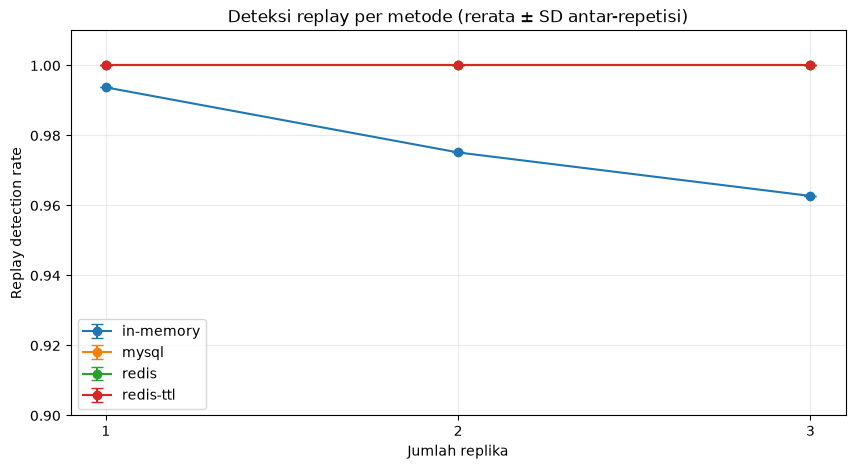

In [4]:

security_cols = [
    "replay_detection_rate", "false_acceptance_rate",
    "legitimate_request_acceptance_rate", "false_rejection_rate"
]
security = (derived.groupby(["method", "replica_count"])[security_cols]
            .agg(["mean", "std", "min", "max"]).reset_index())
security.columns = [
    "_".join(str(x) for x in col if str(x) != "").rstrip("_")
    if isinstance(col, tuple) else col for col in security.columns
]
display(security)

fig, ax = plt.subplots(figsize=(10, 5))
for method, group in derived.groupby("method"):
    g = group.groupby("replica_count")["replay_detection_rate"].agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=4, label=method)
ax.set(xticks=[1,2,3], ylim=(0.90,1.01),
       xlabel="Jumlah replika", ylabel="Replay detection rate",
       title="Deteksi replay per metode (rerata ± SD antar-repetisi)")
ax.grid(alpha=.25)
ax.legend()
plt.show()



### Interpretasi keamanan

- In-memory memperlihatkan penurunan tingkat deteksi saat replika bertambah. Ini konsisten dengan sifat state yang hanya hidup pada proses lokal: replay yang diarahkan ke proses berbeda tidak otomatis berbagi catatan `jti`.
- Redis, Redis TTL, dan MySQL menunjukkan deteksi replay 100% pada skenario dan repetisi yang diamati.
- Hasil 100% berarti tidak ditemukan false acceptance pada sampel uji ini; bukan jaminan probabilitas false acceptance di produksi adalah nol.
- Legitimate request acceptance dan false rejection harus dibaca bersama: kontrol replay yang terlalu agresif juga dapat menolak request sah.



## 6. Analisis lintas replika

Cross-replica replay menguji apakah `jti` yang telah dikonsumsi pada satu replika tetap dikenali ketika replay diarahkan ke replika lain. Pada satu replika, metrik ini tidak relevan sehingga nilai kosong/NaN memang diharapkan.



In [5]:

cross = (derived[derived["replica_count"] > 1]
         .groupby(["method", "replica_count"])["cross_replica_replay_detection_rate"]
         .agg(["mean", "std", "min", "max"]).reset_index())
display(cross)


,method,replica_count,mean,std,min,max
0,in-memory,2,0.0,0.0,0.0,0.0
1,in-memory,3,0.0,0.0,0.0,0.0
2,mysql,2,1.0,0.0,1.0,1.0
3,mysql,3,1.0,0.0,1.0,1.0
4,redis,2,1.0,0.0,1.0,1.0
5,redis,3,1.0,0.0,1.0,1.0
6,redis-ttl,2,1.0,0.0,1.0,1.0
7,redis-ttl,3,1.0,0.0,1.0,1.0



### Interpretasi lintas replika

Pada konfigurasi multi-replika, hasil in-memory menunjukkan keterbatasan state process-local. Redis, Redis TTL, dan MySQL menunjukkan bahwa state bersama memungkinkan deteksi replay lintas replika pada workload yang diuji. Klaim ini berlaku pada konfigurasi routing yang lolos validasi; ia tidak dengan sendirinya membuktikan ketahanan terhadap partition jaringan, failover, atau kehilangan data store.



## 7. Analisis performa

Latency end-to-end adalah waktu HTTP yang diamati runner untuk fase `performance`; latency replay-store adalah durasi operasi `consume()` internal. Throughput dihitung oleh skrip dari jumlah request fase performance dibagi rentang waktu wall-clock yang tercatat.

**Peringatan metodologis:** request-level latency berguna untuk menggambarkan distribusi observasi, tetapi request dalam satu repetisi tidak independen. Karena itu, perbandingan statistik eksploratif menggunakan tiga rerata repetisi per metode dan jumlah replika. Hasil inferensial dengan n=3 per kelompok memiliki daya rendah dan interval ketidakpastian lebar.


,method,replica_count,latency_mean_ms,latency_sd_between_repetitions,latency_p95_ms,latency_p99_ms,store_latency_mean_ms,store_latency_p95_ms,throughput_rps
0,in-memory,1,31.757,1.757,86.004,93.275,0.020,0.032,318.691
1,in-memory,2,39.443,1.852,107.969,112.596,0.028,0.048,282.580
2,in-memory,3,40.270,10.436,86.064,89.033,0.038,0.073,265.702
3,mysql,1,45.248,4.769,120.348,126.414,9.781,24.459,212.571
4,mysql,2,39.321,2.995,107.189,112.091,6.833,17.902,248.565
5,mysql,3,36.746,3.085,94.412,98.908,5.918,16.132,252.369
6,redis,1,38.815,1.653,99.614,103.021,4.148,13.525,304.869
7,redis,2,37.061,5.830,96.384,99.495,1.474,5.501,310.417
8,redis,3,32.143,0.080,81.663,85.689,0.552,1.536,322.061
9,redis-ttl,1,38.580,2.589,105.478,107.532,4.089,13.659,320.020


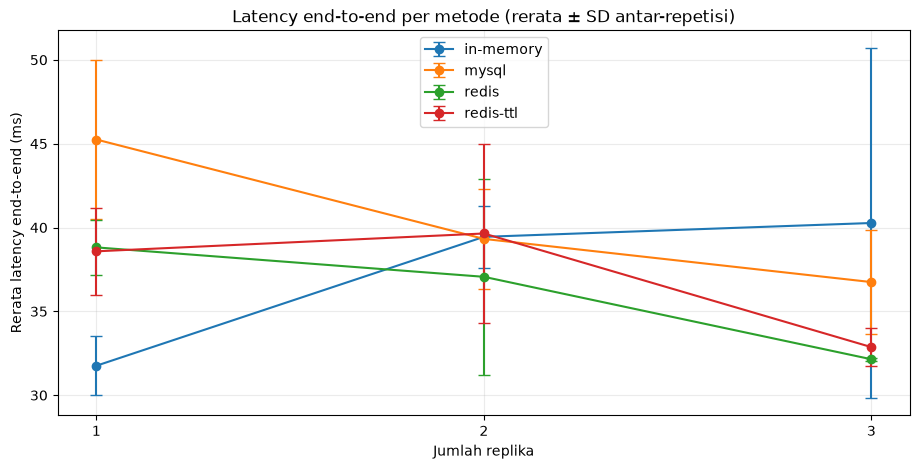

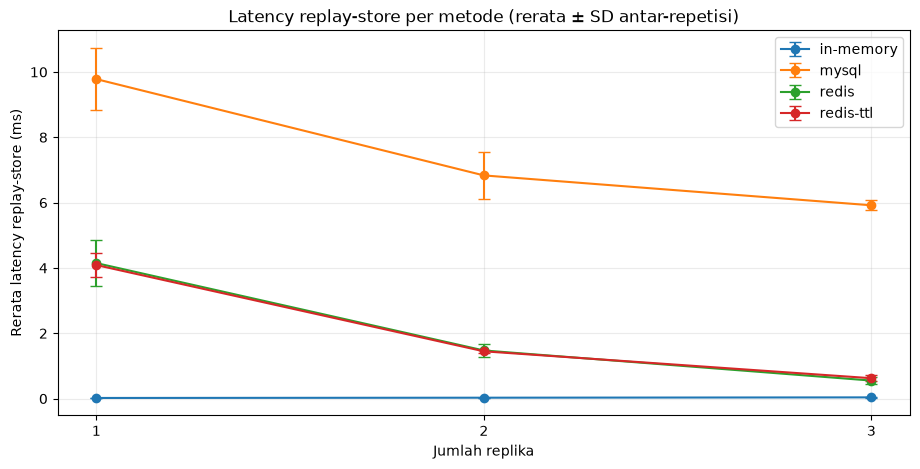

In [6]:

perf = (derived.groupby(["method", "replica_count"])
        .agg(latency_mean_ms=("latency_mean_ms", "mean"),
             latency_sd_between_repetitions=("latency_mean_ms", "std"),
             latency_p95_ms=("latency_p95_ms", "mean"),
             latency_p99_ms=("latency_p99_ms", "mean"),
             store_latency_mean_ms=("store_latency_mean_ms", "mean"),
             store_latency_p95_ms=("store_latency_p95_ms", "mean"),
             throughput_rps=("throughput_rps", "mean"))
        .reset_index())
display(perf.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
for method, group in derived.groupby("method"):
    g = group.groupby("replica_count")["latency_mean_ms"].agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=4, label=method)
ax.set(xticks=[1,2,3], xlabel="Jumlah replika",
       ylabel="Rerata latency end-to-end (ms)",
       title="Latency end-to-end per metode (rerata ± SD antar-repetisi)")
ax.grid(alpha=.25)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
for method, group in derived.groupby("method"):
    g = group.groupby("replica_count")["store_latency_mean_ms"].agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", capsize=4, label=method)
ax.set(xticks=[1,2,3], xlabel="Jumlah replika",
       ylabel="Rerata latency replay-store (ms)",
       title="Latency replay-store per metode (rerata ± SD antar-repetisi)")
ax.grid(alpha=.25)
ax.legend()
plt.show()



## 8. Pemeriksaan statistik eksploratif

### 8.1 Metode

Untuk setiap jumlah replika, notebook membandingkan rerata latency end-to-end per repetisi antar empat metode menggunakan **Kruskal–Wallis**. Uji ini dipilih sebagai pemeriksaan omnibus nonparametrik yang tidak mensyaratkan normalitas, tetapi tetap memerlukan unit observasi yang independen. Tiga repetisi per metode merupakan sampel sangat kecil; karena itu p-value hanya bersifat eksploratif.

Jika uji omnibus menghasilkan p < 0,05, notebook juga menghitung perbandingan pasangan Mann–Whitney U dan mengoreksi p-value dengan metode Holm dalam keluarga pasangan pada jumlah replika tersebut. Dengan n=3, hasil pasangan tetap tidak stabil.

**Tidak dilakukan uji pada setiap request** karena itu akan memperlakukan request yang saling bergantung sebagai sampel independen (*pseudoreplication*). Tidak dilakukan klaim signifikansi untuk keamanan 100% karena kejadian replay berkelompok dalam skenario/batch dan jumlah repetisi hanya tiga.

### 8.2 Hasil uji


In [7]:

try:
    from scipy.stats import kruskal, mannwhitneyu
    from statsmodels.stats.multitest import multipletests
    SCIPY_AVAILABLE = True
except Exception as exc:
    SCIPY_AVAILABLE = False
    print("Paket scipy/statsmodels tidak tersedia:", repr(exc))

stat_rows = []
pair_rows = []
if SCIPY_AVAILABLE:
    for replicas in (1, 2, 3):
        subset = derived[derived["replica_count"] == replicas]
        groups = [
            subset.loc[subset["method"] == method, "latency_mean_ms"].dropna().to_numpy()
            for method in ("in-memory", "redis", "redis-ttl", "mysql")
        ]
        if all(len(g) >= 2 for g in groups):
            h, p = kruskal(*groups)
            stat_rows.append({"replica_count": replicas, "test": "Kruskal-Wallis",
                              "H": h, "p_value": p, "n_per_method": [len(g) for g in groups]})
            if p < 0.05:
                methods = ("in-memory", "redis", "redis-ttl", "mysql")
                raw = []
                pairs = []
                for i in range(len(methods)):
                    for j in range(i+1, len(methods)):
                        a = subset.loc[subset["method"] == methods[i], "latency_mean_ms"].dropna()
                        b = subset.loc[subset["method"] == methods[j], "latency_mean_ms"].dropna()
                        u, pv = mannwhitneyu(a, b, alternative="two-sided", method="auto")
                        pairs.append((methods[i], methods[j], u, pv))
                        raw.append(pv)
                adjusted = multipletests(raw, method="holm")[1]
                for (m1,m2,u,pv), pa in zip(pairs, adjusted):
                    pair_rows.append({"replica_count": replicas, "method_1": m1,
                                      "method_2": m2, "U": u,
                                      "p_raw": pv, "p_holm": pa})
else:
    print("Lewati uji inferensial; instal scipy dan statsmodels untuk menjalankan sel ini.")

kw_results = pd.DataFrame(stat_rows)
pair_results = pd.DataFrame(pair_rows)
display(kw_results if not kw_results.empty else Markdown("Tidak ada uji omnibus yang dapat dihitung."))
display(pair_results if not pair_results.empty else Markdown(
    "Tidak ada uji pasangan yang dijalankan (omnibus tidak signifikan atau paket tidak tersedia)."
))


Paket scipy/statsmodels tidak tersedia: ModuleNotFoundError("No module named 'scipy'")
Lewati uji inferensial; instal scipy dan statsmodels untuk menjalankan sel ini.


Tidak ada uji omnibus yang dapat dihitung.

Tidak ada uji pasangan yang dijalankan (omnibus tidak signifikan atau paket tidak tersedia).


### 8.3 Cara membaca uji statistik

- p-value Kruskal–Wallis yang kecil hanya menunjukkan bukti adanya perbedaan distribusi rerata latency repetisi di antara setidaknya dua metode pada jumlah replika tersebut.
- Uji omnibus tidak mengidentifikasi pasangan mana yang berbeda; itu sebabnya uji pasangan hanya dijalankan setelah omnibus signifikan.
- p-value terkoreksi Holm digunakan untuk mengendalikan family-wise error pada enam pasangan metode untuk satu jumlah replika.
- Jika hasil tidak signifikan, itu **bukan** bukti bahwa performa identik. Dengan tiga repetisi, uji mungkin tidak memiliki daya untuk mendeteksi perbedaan.
- Analisis ini tidak menguji equivalence/non-inferiority dan tidak mengukur CPU atau RAM.



## 9. Persistensi replay state setelah restart

Skrip validasi memeriksa bahwa `jti` yang sama terdeteksi sebelum restart, lalu mengamati hasil setelah restart. Ringkasan berikut dihitung dari keluaran metrik tervalidasi.


In [8]:

restart = (derived.groupby("method")["restart_state_retained"]
           .agg(observations="count", retained_rate="mean").reset_index())
display(restart)


,method,observations,retained_rate
0,in-memory,9,0.0
1,mysql,9,1.0
2,redis,9,1.0
3,redis-ttl,9,1.0



### Interpretasi restart

Untuk In-memory, hilangnya state setelah proses restart konsisten dengan penyimpanan yang hanya berada di memori proses. Untuk store bersama, state yang tetap dikenali setelah restart konsisten dengan persistensi state di luar proses Order Service. Interpretasi ini terbatas pada restart yang diuji; tidak mencakup restart/restore Redis atau MySQL, failover, replikasi database, backup, atau skenario kehilangan storage.



## 10. Pemeriksaan eksekusi protected operation dan error

Replay protection diharapkan mencegah protected operation dijalankan ketika token telah digunakan atau store mengalami error. Kita tampilkan hitungan yang berasal dari request-level observations.


In [9]:

outcomes = (requests.groupby(["method", "replica_count", "actual_outcome"], dropna=False)
            .agg(requests=("request_id", "size"),
                 protected_operation_executions=("protected_operation_executed", lambda s: s.eq(True).sum()))
            .reset_index())
display(outcomes)

error_summary = (derived.groupby(["method", "replica_count"])
                 [["store_error_count", "request_error_count", "service_error_count"]]
                 .sum().reset_index())
display(error_summary)


,method,replica_count,actual_outcome,requests,protected_operation_executions
0,in-memory,1,accepted,1215,1215
1,in-memory,1,replay_detected,477,0
2,in-memory,2,accepted,1227,1227
3,in-memory,2,replay_detected,471,0
4,in-memory,3,accepted,1233,1233
5,in-memory,3,replay_detected,465,0
6,mysql,1,accepted,1212,1212
7,mysql,1,replay_detected,480,0
8,mysql,2,accepted,1215,1215
9,mysql,2,replay_detected,483,0


,method,replica_count,store_error_count,request_error_count,service_error_count
0,in-memory,1,0,0,0
1,in-memory,2,0,0,0
2,in-memory,3,0,0,0
3,mysql,1,0,0,0
4,mysql,2,0,0,0
5,mysql,3,0,0,0
6,redis,1,0,0,0
7,redis,2,0,0,0
8,redis,3,0,0,0
9,redis-ttl,1,0,0,0



## 11. Jawaban sementara terhadap pertanyaan penelitian

**RQ1 — Keamanan.** Pada dataset ini, Redis, Redis TTL, dan MySQL mencapai replay detection 100% pada seluruh jumlah replika. In-memory menunjukkan false acceptance yang meningkat seiring jumlah replika.

**RQ2 — Skalabilitas replika.** Perbedaan paling jelas terlihat pada replay lintas replika: state process-local tidak memberikan koordinasi antarproses, sedangkan tiga pendekatan shared-state berhasil mendeteksi replay lintas replika dalam skenario tervalidasi.

**RQ3 — Performa.** Tabel latency dan throughput menunjukkan trade-off yang perlu dilaporkan secara numerik. Uji statistik hanya eksploratif karena tiga repetisi per kelompok. Hindari menyebut suatu metode “secara signifikan lebih cepat” kecuali uji, asumsi, dan ukuran sampel mendukungnya; bahkan ketika p < 0,05, keterbatasan n harus disebut.

**RQ4 — Persistensi.** Observasi restart menunjukkan perbedaan antara state lokal proses dan state pada penyimpanan bersama sesuai skenario yang diuji.

Pernyataan di atas merupakan ringkasan deskriptif yang harus dibaca bersama tabel hasil aktual di atas, bukan klaim universal.



## 12. Threats to validity dan batas interpretasi

1. **Jumlah repetisi kecil.** Tiga repetisi per konfigurasi membatasi presisi estimasi dan daya uji statistik.
2. **Satu lingkungan eksperimen.** Performa dipengaruhi perangkat keras, OS, versi runtime, konfigurasi store, dan kondisi host.
3. **Tidak ada pengukuran utilisasi resource.** CPU dan process memory utilization tidak disampling. Spesifikasi perangkat bukan metrik utilisasi.
4. **Satu konfigurasi database aktual.** Run ini mencatat MySQL 8.4.11/InnoDB, bukan MariaDB. Hasil tidak boleh digabung atau dilabeli MariaDB.
5. **Satu semantik token.** Kesimpulan berlaku pada one-time-use service token dengan `jti`, bukan semua pola penggunaan JWT.
6. **Rentang skala terbatas.** Hanya 1–3 replika dan concurrency level 1, 10, 50 yang diuji.
7. **Kondisi store terbatas.** Dataset ini tidak membuktikan ketahanan terhadap network partition, failover, eviction, kehilangan persistence, atau beban store eksternal.
8. **Tidak ada randomisasi urutan metode yang dibuktikan oleh metadata.** Efek urutan/warm-up dan perubahan kondisi host belum dapat dikesampingkan.
9. **Validasi mengikuti aturan skrip.** Skrip memberi pemeriksaan integritas yang kuat, tetapi tidak membuktikan bahwa seluruh asumsi desain atau implementasi bebas dari cacat.

### Metadata dan versi kode

Metadata merekam commit eksperimen `e23767c05139b7fcbf389ceb08b7abb1c4dbfef5`. Notebook analisis dapat berada pada commit yang lebih baru. Dalam publikasi, laporkan commit eksperimen yang direkam metadata dan commit analisis yang benar-benar digunakan secara terpisah.



## 13. Kesimpulan

Dalam batas konfigurasi yang diuji, pendekatan replay-state bersama (Redis, Redis TTL, dan MySQL/InnoDB) menunjukkan deteksi replay penuh dan konsistensi lintas replika, sedangkan In-memory mengalami false acceptance yang meningkat ketika jumlah replika bertambah. Observasi restart juga memperlihatkan bahwa state process-local tidak bertahan setelah proses dimulai ulang, berbeda dari state pada penyimpanan bersama.

Performa harus dilaporkan sebagai trade-off terukur antara latency end-to-end, latency replay-store, dan throughput, dengan penekanan bahwa hanya tiga repetisi tersedia. Dataset ini tidak mendukung klaim tentang utilisasi CPU/RAM atau signifikansi yang kuat untuk populasi produksi.

**Kesimpulan utama:** untuk arsitektur Order Service multi-replika pada semantik one-time-use token yang diuji, penyimpanan replay state bersama memberikan konsistensi replay protection yang lebih baik daripada state process-local. Pemilihan antara Redis, Redis TTL, dan MySQL perlu mempertimbangkan karakteristik latency, lifecycle state, kebutuhan persistensi, dan operasional store.



## Lampiran A. Definisi metrik

| Metrik | Definisi operasional |
|---|---|
| Replay detection rate | Replay yang ditolak / seluruh peluang replay menurut perhitungan skrip |
| False acceptance rate | Peluang replay yang diterima / seluruh peluang replay |
| Legitimate acceptance rate | Request legitimate yang diterima / seluruh request legitimate |
| False rejection rate | Request legitimate yang tidak diterima / seluruh request legitimate |
| Cross-replica replay detection | Replay lintas replika yang ditolak / observasi replay lintas replika |
| End-to-end latency | Durasi request HTTP yang diamati runner pada fase performance |
| Replay-store latency | Durasi internal operasi `consume()` pada replay store |
| Throughput | Request fase performance / rentang waktu wall-clock pengamatan |
| Restart state retained | Apakah replay atas `jti` yang sama tetap ditolak setelah restart |

Metrik turunan dan aturan pembulatan mengikuti `analysis/analyze_replay_protection.py`. Untuk replikasi hasil, gunakan skrip tersebut bersama file mentah dari direktori run.


In [10]:

# Ringkasan akhir yang mudah diekspor/dikutip.
final_summary = (derived.groupby(["method", "replica_count"], as_index=False)
                 .agg(replay_detection_rate=("replay_detection_rate", "mean"),
                      false_acceptance_rate=("false_acceptance_rate", "mean"),
                      cross_replica_detection=("cross_replica_replay_detection_rate", "mean"),
                      latency_mean_ms=("latency_mean_ms", "mean"),
                      latency_p95_ms=("latency_p95_ms", "mean"),
                      store_latency_mean_ms=("store_latency_mean_ms", "mean"),
                      throughput_rps=("throughput_rps", "mean")))
display(final_summary.round(4))

print("VALIDATION:", json.dumps(validation_report, indent=2))


,method,replica_count,replay_detection_rate,false_acceptance_rate,cross_replica_detection,latency_mean_ms,latency_p95_ms,store_latency_mean_ms,throughput_rps
0,in-memory,1,0.9938,0.0063,NaN,31.7575,86.0038,0.0197,318.6907
1,in-memory,2,0.9752,0.0248,0.0,39.4430,107.9693,0.0278,282.5801
2,in-memory,3,0.9627,0.0373,0.0,40.2695,86.0641,0.0377,265.7021
3,mysql,1,1.0000,0.0000,NaN,45.2477,120.3483,9.7811,212.5713
4,mysql,2,1.0000,0.0000,1.0,39.3214,107.1889,6.8331,248.5647
5,mysql,3,1.0000,0.0000,1.0,36.7464,94.4122,5.9183,252.3690
6,redis,1,1.0000,0.0000,NaN,38.8148,99.6140,4.1485,304.8686
7,redis,2,1.0000,0.0000,1.0,37.0607,96.3840,1.4741,310.4170
8,redis,3,1.0000,0.0000,1.0,32.1435,81.6632,0.5521,322.0612
9,redis-ttl,1,1.0000,0.0000,NaN,38.5801,105.4782,4.0887,320.0199


VALIDATION: {
  "experiment_id": "replay-2026-11-12T21-04-35-038Z-24266fa7",
  "valid": true,
  "scenario_rows": 36,
  "valid_scenarios": 36,
  "invalid_scenarios": 0,
  "comparison_generated": true,
  "failures": []
}
